# Predicción de la carga de calefacción de edificios mediante Machine Learning

Proyecto final — Fase 4: Machine Learning clásico

## 1. Introducción

### Problema y objetivo

El objetivo de este proyecto es predecir la carga de calefacción
de edificios a partir de ocho características físicas y arquitectónicas.

La carga de calefacción representa la necesidad de calefacción del
edificio bajo las condiciones consideradas en la simulación.

La pregunta principal es: ¿hasta qué punto estas características
permiten predecir la carga de calefacción mediante modelos de
Machine Learning clásico?

### Dataset

Se utiliza el dataset Energy Efficiency de UCI Machine Learning
Repository, con 768 configuraciones simuladas de edificios,
ocho variables de entrada y dos variables objetivo: carga de
calefacción y carga de refrigeración.

En este proyecto se predice únicamente la carga de calefacción
(`heating_load`). La carga de refrigeración (`cooling_load`)
no se utiliza como variable de entrada.

Las características consideradas son la compacidad relativa,
la superficie total, la superficie de las paredes, la superficie
del tejado, la altura total, la orientación, el área acristalada
y la distribución del acristalamiento.

### Metodología

Se comparan regresión lineal, Ridge, árbol de decisión y Random Forest.

Los datos se dividen en entrenamiento y prueba. La comparación y
el ajuste de modelos se realizan mediante validación cruzada sobre
el conjunto de entrenamiento. Se presentan métricas de entrenamiento
y prueba, y se analiza el sobreajuste, los errores y la importancia
de las variables.

Las métricas utilizadas son MAE, RMSE y R². Las limitaciones del
procedimiento, incluida la consulta inicial del conjunto de prueba
durante la exploración, se explican en las conclusiones.

### Alcance

Este proyecto tiene una finalidad educativa: demostrar la aplicación
de un flujo de regresión supervisada de principio a fin.

Los datos son simulados, no mediciones de edificios reales. El modelo
no constituye una herramienta validada para diseñar edificios ni
para tomar decisiones de ingeniería.

### Fuente de los datos

Tsanas, A. y Xifara, A. (2012). Energy Efficiency [Dataset].
UCI Machine Learning Repository.
DOI: 10.24432/C51307.

In [107]:
import pandas as pd
from google.colab import files
files.upload();

Saving ENB2012_data.xlsx to ENB2012_data (1).xlsx


## 1. Carga de los datos

Cargamos el archivo ENB2012_data.xlsx en un DataFrame llamado df.

In [109]:
df=pd.read_excel("ENB2012_data.xlsx")

## 2. Exploración inicial

Revisamos las primeras filas, el tamaño del conjunto, los tipos
de datos, los valores ausentes, los duplicados y las estadísticas
descriptivas.

El conjunto contiene 768 filas y 10 columnas, sin valores
ausentes ni filas duplicadas.

In [110]:
df.head()

,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


In [111]:
df.shape

(768, 10)

In [112]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X1      768 non-null    float64
 1   X2      768 non-null    float64
 2   X3      768 non-null    float64
 3   X4      768 non-null    float64
 4   X5      768 non-null    float64
 5   X6      768 non-null    int64  
 6   X7      768 non-null    float64
 7   X8      768 non-null    int64  
 8   Y1      768 non-null    float64
 9   Y2      768 non-null    float64
dtypes: float64(8), int64(2)
memory usage: 60.1 KB


In [113]:
df.duplicated().sum()

np.int64(0)

In [114]:
df.describe()

,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
count,768.000000,768.000000,768.000000,768.000000,768.00000,768.000000,768.000000,768.00000,768.000000,768.000000
mean,0.764167,671.708333,318.500000,176.604167,5.25000,3.500000,0.234375,2.81250,22.307195,24.587760
std,0.105777,88.086116,43.626481,45.165950,1.75114,1.118763,0.133221,1.55096,10.090204,9.513306
min,0.620000,514.500000,245.000000,110.250000,3.50000,2.000000,0.000000,0.00000,6.010000,10.900000
25%,0.682500,606.375000,294.000000,140.875000,3.50000,2.750000,0.100000,1.75000,12.992500,15.620000
50%,0.750000,673.750000,318.500000,183.750000,5.25000,3.500000,0.250000,3.00000,18.950000,22.080000
75%,0.830000,741.125000,343.000000,220.500000,7.00000,4.250000,0.400000,4.00000,31.667500,33.132500
max,0.980000,808.500000,416.500000,220.500000,7.00000,5.000000,0.400000,5.00000,43.100000,48.030000


## 3. Nombres de las columnas

Sustituimos los nombres originales por nombres descriptivos
para facilitar la lectura del análisis.

In [115]:
df=df.rename(columns={"X1":"relative_compactness","X2":"surface_area","X3":"wall_area","X4":"roof_area","X5":"overall_height","X6":"orientation","X7":"glazing_area","X8":"glazing_area_distribution","Y1":"heating_load","Y2":"cooling_load"})

In [116]:
df.head()

,relative_compactness,surface_area,wall_area,roof_area,overall_height,orientation,glazing_area,glazing_area_distribution,heating_load,cooling_load
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


In [117]:
df.columns

Index(['relative_compactness', 'surface_area', 'wall_area', 'roof_area',
       'overall_height', 'orientation', 'glazing_area',
       'glazing_area_distribution', 'heating_load', 'cooling_load'],
      dtype='object')

## 4. Revisión de variables categóricas

Revisamos los valores presentes en las variables de orientación
y distribución del área acristalada.

In [118]:
df["orientation"].unique()

array([2, 3, 4, 5])

In [119]:
df["glazing_area_distribution"].unique()

array([0, 1, 2, 3, 4, 5])

## 5. Selección de variables

Definimos `heating_load` como variable objetivo (`y`) y seleccionamos
ocho variables explicativas para formar `X`. La variable `cooling_load`
no se incluye entre las variables predictoras.

In [120]:
y=df.heating_load
features=['relative_compactness', 'surface_area', 'wall_area', 'roof_area',
       'overall_height', 'orientation', 'glazing_area',
       'glazing_area_distribution']
X=df[features]

In [121]:
y.shape

(768,)

In [122]:
X.shape

(768, 8)

## 6. División en entrenamiento y prueba

Dividimos los datos en un conjunto de entrenamiento y otro de prueba,
reservando el 20 % para la prueba.

In [123]:
from sklearn.model_selection import train_test_split

In [124]:
X_train,X_test,y_train,y_test=train_test_split(X,y,random_state=42,test_size=0.20)

In [125]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (614, 8)
X_test: (154, 8)
y_train: (614,)
y_test: (154,)


## 7. Análisis exploratorio del conjunto de entrenamiento

Examinamos la distribución de la variable objetivo y de las variables
explicativas. También representamos la relación de algunas características
del edificio con la carga de calefacción.

### 7.1. Distribución de la variable objetivo

Representamos la distribución de la carga de calefacción en el conjunto
de entrenamiento.

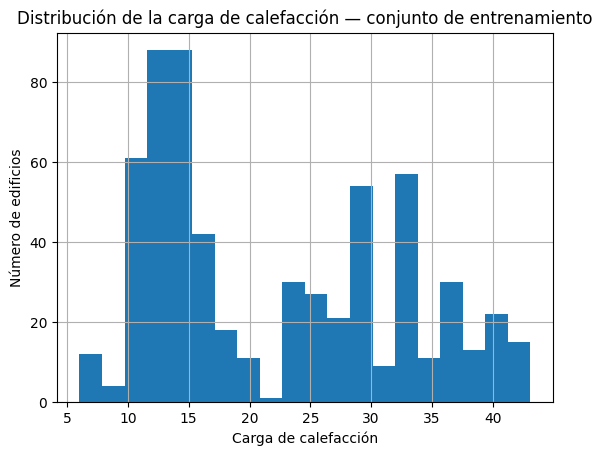

In [126]:
import matplotlib.pyplot as plt
y_train.hist(bins=20)
plt.title("Distribución de la carga de calefacción — conjunto de entrenamiento")
plt.xlabel("Carga de calefacción")
plt.ylabel("Número de edificios")
plt.show()

### 7.2. Distribución de las variables explicativas

Representamos las distribuciones de las ocho variables seleccionadas
en el conjunto de entrenamiento.

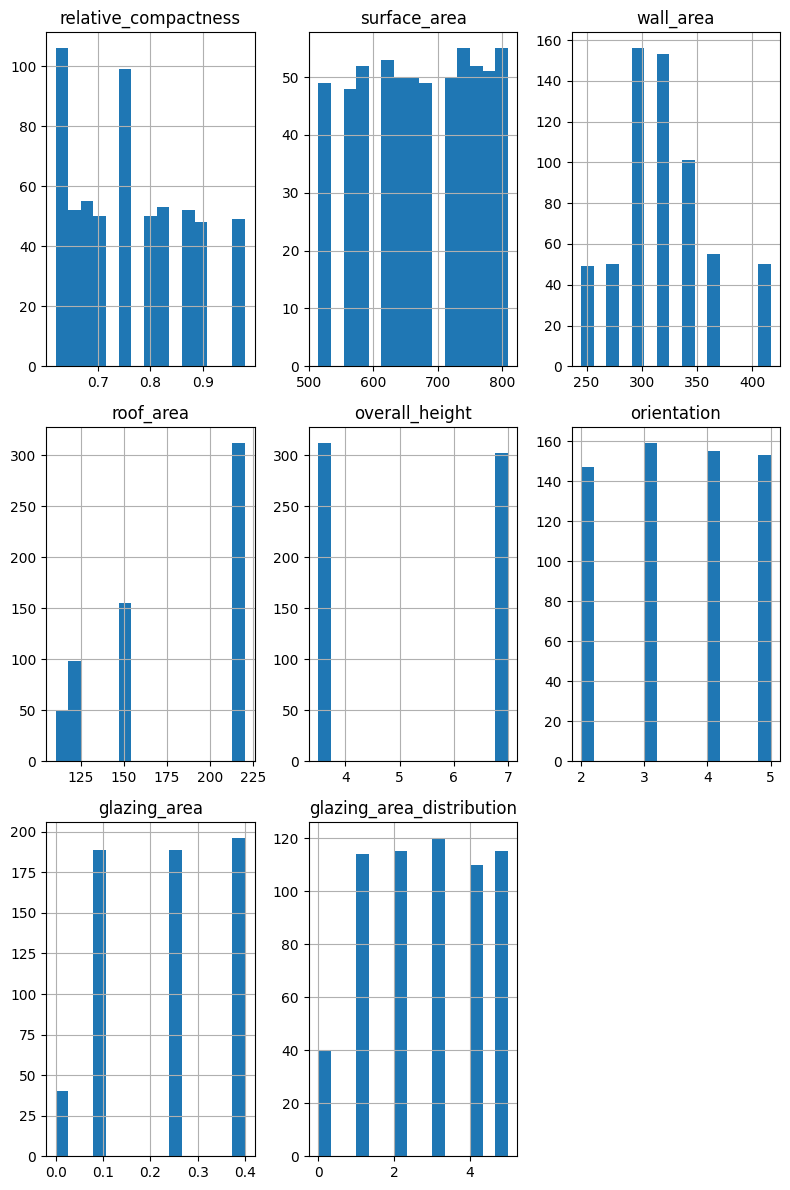

In [127]:
X_train.hist(bins=15, figsize=(8,12))
plt.tight_layout()
plt.show()

### 7.3. Relación entre las variables explicativas y la carga de calefacción

Representamos la carga de calefacción frente a la compacidad relativa,
la altura total, la superficie total y el área acristalada, utilizando
los datos de entrenamiento.

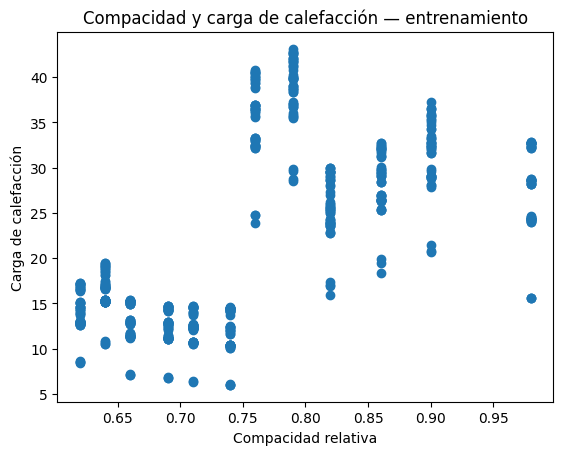

In [128]:
plt.scatter(X_train.relative_compactness, y_train)
plt.title("Compacidad y carga de calefacción — entrenamiento")
plt.xlabel("Compacidad relativa")
plt.ylabel("Carga de calefacción")
plt.show()

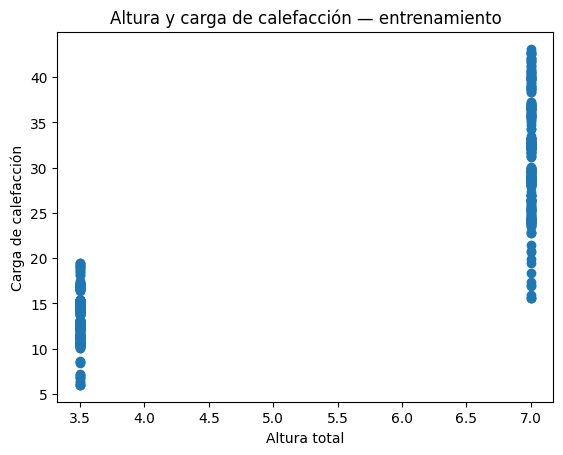

In [129]:
plt.scatter(X_train.overall_height, y_train)
plt.title("Altura y carga de calefacción — entrenamiento")
plt.xlabel("Altura total")
plt.ylabel("Carga de calefacción")
plt.show()

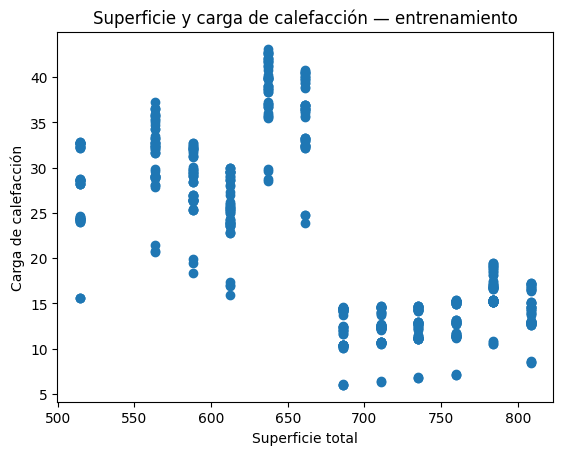

In [130]:
plt.scatter(X_train.surface_area, y_train)
plt.xlabel("Superficie total")
plt.ylabel("Carga de calefacción")
plt.title("Superficie y carga de calefacción — entrenamiento")
plt.show()

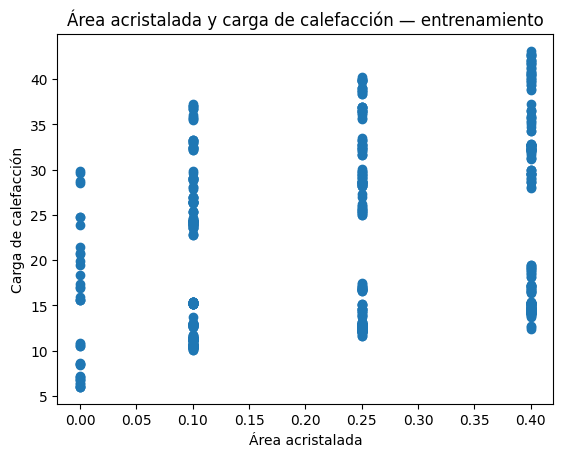

In [131]:
plt.scatter(X_train.glazing_area, y_train)
plt.xlabel("Área acristalada")
plt.ylabel("Carga de calefacción")
plt.title("Área acristalada y carga de calefacción — entrenamiento")
plt.show()

## 8. Modelo de regresión lineal

Una vez explorados los datos de entrenamiento, pasamos a construir
un modelo de regresión lineal para predecir la carga de calefacción
a partir de las ocho variables explicativas seleccionadas.

In [132]:
from sklearn.linear_model import LinearRegression

In [133]:
baseline_model = LinearRegression()

In [134]:
baseline_model.fit(X_train, y_train)

LinearRegression()

In [135]:
train_preds=baseline_model.predict(X_train)

In [136]:
print(train_preds[:5])

[27.98544026 17.90203144 29.23072882 30.13365039 11.56389241]


In [137]:
from sklearn.metrics import mean_absolute_error

In [138]:
train_mae=mean_absolute_error(y_train, train_preds)

In [139]:
print(train_mae)

2.0413636834362476


In [140]:
from sklearn.metrics import root_mean_squared_error

In [141]:
train_rmse= root_mean_squared_error(y_train, train_preds)

In [142]:
print(train_rmse)

2.893118785420839


In [143]:
from sklearn.metrics import r2_score
train_r2 = r2_score(y_train, train_preds)
print(train_r2)

0.9170648846622238


In [144]:
print("Se ha entrenado una regresión lineal como modelo base utilizando las ocho variables de entrada. En entrenamiento se obtiene un MAE de 2,04, un RMSE de 2,89 y un R² de 0,9171. Estos resultados describen el ajuste sobre los datos utilizados para entrenar, pero todavía no permiten concluir cómo generaliza el modelo a datos nuevos.")

Se ha entrenado una regresión lineal como modelo base utilizando las ocho variables de entrada. En entrenamiento se obtiene un MAE de 2,04, un RMSE de 2,89 y un R² de 0,9171. Estos resultados describen el ajuste sobre los datos utilizados para entrenar, pero todavía no permiten concluir cómo generaliza el modelo a datos nuevos.


## 9. Modelo de árbol de decisión

Entrenamos un árbol de decisión utilizando las mismas variables
de entrada y el mismo conjunto de entrenamiento.

In [145]:
from sklearn.tree import DecisionTreeRegressor

In [146]:
tree_model=DecisionTreeRegressor(random_state=42)

In [147]:
tree_model.fit(X_train, y_train)

DecisionTreeRegressor(random_state=42)

In [148]:
tree_train_preds=tree_model.predict(X_train)

In [149]:
tree_train_rmse=root_mean_squared_error(y_train, tree_train_preds)
print(tree_train_rmse)

1.2416713323179967e-16


## 10. Comparación mediante validación cruzada

Evaluamos el árbol de decisión y la regresión lineal mediante
validación cruzada de cinco particiones sobre los datos de entrenamiento.
Para comparar ambos modelos, calculamos el RMSE medio de validación.

In [150]:
from sklearn.model_selection import cross_val_score

In [151]:
tree_cv_scores = cross_val_score(
    tree_model,
    X_train,
    y_train,
    cv=5,
    scoring="neg_root_mean_squared_error"
)

In [152]:
tree_cv_rmse=-tree_cv_scores.mean()
print(tree_cv_rmse)

0.5801073294099351


In [153]:
baseline_cv_scores = cross_val_score(
    baseline_model,
    X_train,
    y_train,
    cv=5,
    scoring="neg_root_mean_squared_error"
)

In [154]:
baseline_cv_rmse=-baseline_cv_scores.mean()
print(baseline_cv_rmse)

2.929179095398513


## 11. Influencia de la profundidad del árbol

Comparamos árboles de decisión con distintas profundidades máximas
mediante validación cruzada de cinco particiones sobre el conjunto
de entrenamiento.

Para cada profundidad, calculamos el RMSE medio de entrenamiento
y de validación. En este experimento no utilizamos el conjunto de prueba.

In [155]:
from sklearn.model_selection import cross_validate

depths = [1, 2, 3, 4, 5, 8, 12, None]
depth_results = []

for depth in depths:
    model = DecisionTreeRegressor(
        max_depth=depth,
        random_state=42
    )

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="neg_root_mean_squared_error",
        return_train_score=True
    )

    depth_results.append({
        "depth": "Sin límite" if depth is None else str(depth),
        "train_rmse": -scores["train_score"].mean(),
        "cv_rmse": -scores["test_score"].mean()
    })

In [156]:
results_df = pd.DataFrame(depth_results)
results_df

,depth,train_rmse,cv_rmse
0,1,4.595191e+00,4.605186
1,2,3.352569e+00,3.374993
2,3,2.326323e+00,2.343200
3,4,1.488656e+00,1.556187
4,5,9.502215e-01,1.017523
5,8,2.451649e-01,0.549978
6,12,4.266593e-02,0.577235
7,Sin límite,5.554054e-17,0.580107


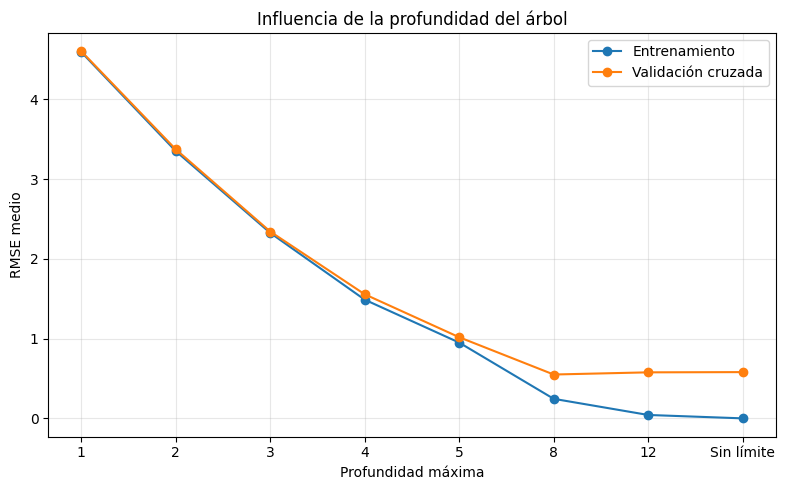

In [157]:
plt.figure(figsize=(8, 5))

plt.plot(
    results_df["depth"],
    results_df["train_rmse"],
    marker="o",
    label="Entrenamiento"
)

plt.plot(
    results_df["depth"],
    results_df["cv_rmse"],
    marker="o",
    label="Validación cruzada"
)

plt.xlabel("Profundidad máxima")
plt.ylabel("RMSE medio")
plt.title("Influencia de la profundidad del árbol")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretación de los resultados

Al aumentar la profundidad de 1 a 8, disminuyen tanto el RMSE de
entrenamiento como el de validación cruzada. Los árboles de menor
profundidad presentan errores elevados en ambos conjuntos, lo que
sugiere que resultan demasiado simples para este problema.

La profundidad 8 obtiene el menor RMSE medio de validación cruzada
entre las configuraciones evaluadas: aproximadamente 0,5500,
frente a un RMSE medio de entrenamiento de 0,2452.

Con profundidad 12 y sin límite, el error de entrenamiento continúa
disminuyendo, pero el de validación aumenta ligeramente hasta 0,5772
y 0,5801, respectivamente. Esta separación entre ambos errores
muestra señales de sobreajuste.

El árbol sin límite alcanza un error de entrenamiento prácticamente
nulo, pero no consigue el mejor resultado de validación. Por tanto,
ajustar mejor los datos de entrenamiento no implica necesariamente
obtener mejores predicciones sobre datos no utilizados para entrenar.

Entre las profundidades probadas, elegiríamos 8 según el RMSE medio
de validación cruzada. Esta elección se realiza utilizando únicamente
el conjunto de entrenamiento.

## 12. Modelo Random Forest

Evaluamos un modelo Random Forest con 100 árboles mediante validación
cruzada de cinco particiones sobre el conjunto de entrenamiento.
Calculamos su RMSE medio para compararlo con los modelos anteriores.

In [158]:
from sklearn.ensemble import RandomForestRegressor

In [159]:
forest_model=RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

In [160]:
forest_cv_scores=cross_val_score(
    forest_model,
    X_train,
    y_train,
    cv=5,
    scoring="neg_root_mean_squared_error"
)

In [161]:
forest_cv_rmse=-forest_cv_scores.mean()
print(forest_cv_scores)

[-0.47183158 -0.53219055 -0.53784298 -0.45370125 -0.55944187]


In [162]:
print("El modelo con menor RMSE medio de validación cruzada fue Random Forest. Frente a la regresión lineal, la mejora fue enorme, mientras que frente al árbol de decisión fue pequeña.")

El modelo con menor RMSE medio de validación cruzada fue Random Forest. Frente a la regresión lineal, la mejora fue enorme, mientras que frente al árbol de decisión fue pequeña.


## 13. Modelo Ridge

Construimos un pipeline que combina el escalado de las variables
con una regresión Ridge, inicialmente con alpha igual a 1.
Evaluamos este modelo mediante validación cruzada de cinco particiones.

In [163]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [164]:
ridge_pipeline=Pipeline([
    ("scaler",StandardScaler()),
    ("model",Ridge(alpha=1.0))
])

In [165]:
ridge_cv_scores=cross_val_score(
    ridge_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="neg_root_mean_squared_error"
)

In [166]:
ridge_cv_rmse=-ridge_cv_scores.mean()
print(ridge_cv_rmse)

2.9307954240703973


## 14. Ajuste del parámetro de regularización

Comparamos distintos valores de alpha mediante validación cruzada.
Primero realizamos la comparación con un bucle y después utilizamos
GridSearchCV para obtener la mejor configuración entre las evaluadas.

In [167]:
alphas=[0.01, 0.1, 1, 10, 100]
ridge_results=[]

In [168]:
ridge_results = []
for alpha in alphas:
  ridge_pipeline=Pipeline([
      ("scaler",StandardScaler()),
      ("model",Ridge(alpha=alpha))
  ])
  ridge_cv_scores = cross_val_score(
      ridge_pipeline,
      X_train,
      y_train,
      cv=5,
      scoring="neg_root_mean_squared_error"
    )

  ridge_cv_rmse = -ridge_cv_scores.mean()
  ridge_results.append({
      "alpha": alpha,
      "cv_rmse": ridge_cv_rmse
  })

In [169]:
print(ridge_results)

[{'alpha': 0.01, 'cv_rmse': np.float64(2.9291574760000207)}, {'alpha': 0.1, 'cv_rmse': np.float64(2.929021044965099)}, {'alpha': 1, 'cv_rmse': np.float64(2.9307954240703973)}, {'alpha': 10, 'cv_rmse': np.float64(2.981680634224315)}, {'alpha': 100, 'cv_rmse': np.float64(3.364457499878477)}]


In [170]:
from sklearn.model_selection import GridSearchCV

In [171]:
param_grid={
    "model__alpha":alphas
}

In [172]:
ridge_search=GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error"
)

In [173]:
ridge_search.fit(X_train,y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('model', Ridge(alpha=100))]),
             param_grid={'model__alpha': [0.01, 0.1, 1, 10, 100]},
             scoring='neg_root_mean_squared_error')

In [174]:
print("Mejor alpha:", ridge_search.best_params_)
print("Mejor RMSE medio:", -ridge_search.best_score_)

Mejor alpha: {'model__alpha': 0.1}
Mejor RMSE medio: 2.929021044965099


In [175]:
best_ridge = ridge_search.best_estimator_
print(best_ridge)

Pipeline(steps=[('scaler', StandardScaler()), ('model', Ridge(alpha=0.1))])


## 15. Evaluación en el conjunto de prueba

Calculamos el RMSE del modelo Ridge seleccionado y de Random Forest
sobre el conjunto de prueba.

In [176]:
ridge_test_pred=best_ridge.predict(X_test)

In [177]:
from sklearn.metrics import root_mean_squared_error
ridge_test_rmse = root_mean_squared_error(y_test,ridge_test_pred)
print(ridge_test_rmse)

3.02637044735845


In [178]:
forest_model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [179]:
forest_test_pred=forest_model.predict(X_test)

In [180]:
forest_test_rmse=root_mean_squared_error(y_test, forest_test_pred)
print(forest_test_rmse)

0.49079847532018817


### Comparación de resultados de los modelos

Reunimos las métricas de entrenamiento y prueba de los cuatro modelos,
junto con su RMSE medio de validación cruzada.

La comparación incluye el árbol de decisión original sin límite de
profundidad. El experimento con distintas profundidades se presenta
por separado en el apartado 11.

In [181]:
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score
)

models_to_compare = [
    ("Regresión lineal", baseline_model, baseline_cv_rmse),
    ("Árbol sin límite", tree_model, tree_cv_rmse),
    ("Random Forest", forest_model, forest_cv_rmse),
    ("Ridge ajustado", best_ridge, -ridge_search.best_score_)
]

comparison_results = []

for name, model, cv_rmse in models_to_compare:
    predictions_train = model.predict(X_train)
    predictions_test = model.predict(X_test)

    comparison_results.append({
        "Modelo": name,
        "Train MAE": mean_absolute_error(y_train, predictions_train),
        "Test MAE": mean_absolute_error(y_test, predictions_test),
        "Train RMSE": root_mean_squared_error(
            y_train, predictions_train
        ),
        "Test RMSE": root_mean_squared_error(
            y_test, predictions_test
        ),
        "Train R2": r2_score(y_train, predictions_train),
        "Test R2": r2_score(y_test, predictions_test),
        "CV RMSE medio": cv_rmse
    })

comparison_df = pd.DataFrame(comparison_results)

comparison_df.round(4)

,Modelo,Train MAE,Test MAE,Train RMSE,Test RMSE,Train R2,Test R2,CV RMSE medio
0,Regresión lineal,2.0414,2.1821,2.8931,3.0254,0.9171,0.9122,2.9292
1,Árbol sin límite,0.0000,0.4248,0.0000,0.6206,1.0000,0.9963,0.5801
2,Random Forest,0.1141,0.3547,0.1742,0.4908,0.9997,0.9977,0.5110
3,Ridge ajustado,2.0409,2.1829,2.8932,3.0264,0.9171,0.9121,2.9290


## 16. Análisis de errores de Random Forest

Comparamos las predicciones de Random Forest con los valores reales.
Calculamos los errores, revisamos los casos con mayor error absoluto
y obtenemos el error absoluto medio.

In [182]:
forest_errors=y_test-forest_test_pred

In [183]:
forest_error_analysis = pd.DataFrame({
    "real": y_test,
    "prediccion": forest_test_pred,
    "error": forest_errors
})
forest_error_analysis.head()

,real,prediccion,error
668,16.47,15.5471,0.9229
324,13.17,13.1532,0.0168
624,32.82,32.8004,0.0196
690,41.32,42.0202,-0.7002
473,16.69,16.8639,-0.1739


In [184]:
forest_error_analysis["error_absoluto"] = forest_error_analysis["error"].abs()
forest_error_analysis.head()

,real,prediccion,error,error_absoluto
668,16.47,15.5471,0.9229,0.9229
324,13.17,13.1532,0.0168,0.0168
624,32.82,32.8004,0.0196,0.0196
690,41.32,42.0202,-0.7002,0.7002
473,16.69,16.8639,-0.1739,0.1739


In [185]:
forest_error_analysis.sort_values(
    by="error_absoluto",
    ascending=False
).head()

,real,prediccion,error,error_absoluto
451,40.12,38.8583,1.2617,1.2617
210,35.45,36.6860,-1.2360,1.2360
259,35.48,36.6858,-1.2058,1.2058
692,40.68,39.4791,1.2009,1.2009
691,42.96,41.8040,1.1560,1.1560


In [186]:
forest_test_mae = forest_error_analysis["error_absoluto"].mean()
print(forest_test_mae)

0.35467402597402614


### Valores reales frente a predicciones

Comparamos las cargas de calefacción reales con las predichas por
Random Forest en el conjunto de prueba. La diagonal representa
una coincidencia exacta entre el valor real y la predicción.

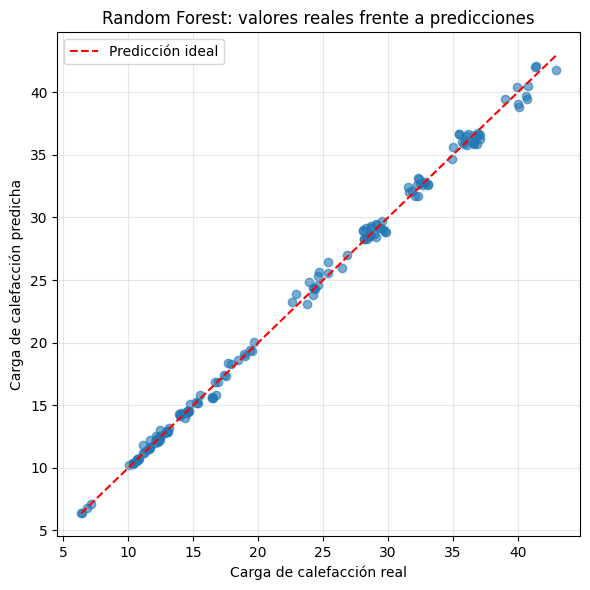

In [187]:
plt.figure(figsize=(6, 6))

plt.scatter(y_test, forest_test_pred, alpha=0.6)

lower = min(y_test.min(), forest_test_pred.min())
upper = max(y_test.max(), forest_test_pred.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    color="red",
    linestyle="--",
    label="Predicción ideal"
)

plt.xlabel("Carga de calefacción real")
plt.ylabel("Carga de calefacción predicha")
plt.title("Random Forest: valores reales frente a predicciones")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Residuos frente a predicciones

Representamos los residuos, calculados como el valor real menos
el predicho, frente a las predicciones del modelo.

Los residuos positivos indican que el modelo ha subestimado la carga
de calefacción; los negativos indican que la ha sobreestimado.

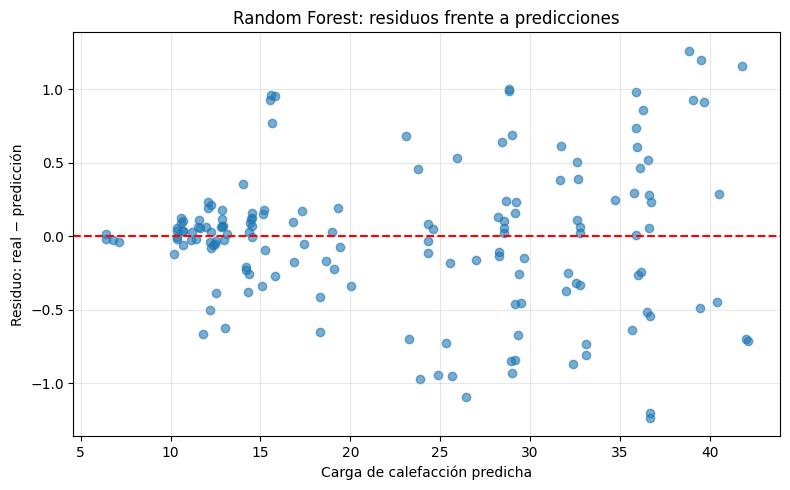

In [188]:
residuals = y_test - forest_test_pred

plt.figure(figsize=(8, 5))

plt.scatter(forest_test_pred, residuals, alpha=0.6)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.xlabel("Carga de calefacción predicha")
plt.ylabel("Residuo: real − predicción")
plt.title("Random Forest: residuos frente a predicciones")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretación de las predicciones y los residuos

En el gráfico de valores reales frente a predicciones, los puntos
se sitúan próximos a la diagonal ideal a lo largo del rango observado.
Esto es coherente con las métricas de Random Forest en el conjunto
de prueba: RMSE de 0,4908, MAE de 0,3547 y R² de 0,9977.

El gráfico de residuos permite observar diferencias que resultan
menos visibles en el gráfico anterior. Aparecen errores tanto
positivos como negativos: el modelo subestima algunas cargas
y sobreestima otras.

Los residuos son especialmente pequeños para las cargas más bajas,
mientras que en las cargas medias y altas presentan mayor dispersión.
Por tanto, la magnitud de los errores no parece uniforme en todo
el rango de predicciones.

Aunque el resultado global es favorable en esta división de los
datos, no implica que el modelo tenga la misma precisión para
cualquier edificio ni que esté validado para aplicaciones reales.

## 17. Importancia de las variables

Recogemos las importancias de las variables proporcionadas por
Random Forest y las ordenamos de mayor a menor.

In [189]:
forest_importances = forest_model.feature_importances_
print(forest_importances)

[0.3946689  0.19284137 0.03383316 0.13536901 0.1509906  0.00073678
 0.07972268 0.01183749]


In [190]:
forest_importance_table = pd.DataFrame({
    "variable": X_train.columns,
    "importancia": forest_importances
})
forest_importance_table

,variable,importancia
0,relative_compactness,0.394669
1,surface_area,0.192841
2,wall_area,0.033833
3,roof_area,0.135369
4,overall_height,0.150991
5,orientation,0.000737
6,glazing_area,0.079723
7,glazing_area_distribution,0.011837


In [191]:
forest_importance_table.sort_values(
    by="importancia",
    ascending=False
)

,variable,importancia
0,relative_compactness,0.394669
1,surface_area,0.192841
4,overall_height,0.150991
3,roof_area,0.135369
6,glazing_area,0.079723
2,wall_area,0.033833
7,glazing_area_distribution,0.011837
5,orientation,0.000737


In [192]:
print("RESULTADOS DE RANDOM FOREST")
print("RMSE medio de validación cruzada:", forest_cv_rmse)
print("RMSE en el conjunto de prueba:", forest_test_rmse)
print("MAE en el conjunto de prueba:", forest_test_mae)

RESULTADOS DE RANDOM FOREST
RMSE medio de validación cruzada: 0.511001643223019
RMSE en el conjunto de prueba: 0.49079847532018817
MAE en el conjunto de prueba: 0.35467402597402614


In [193]:
print("RESULTADOS DE VALIDACIÓN CRUZADA")
print("Regresión lineal:", baseline_cv_rmse)
print("Árbol de decisión:", tree_cv_rmse)
print("Random Forest:", forest_cv_rmse)
print("Ridge ajustado:", -ridge_search.best_score_)

print("\nRESULTADOS DE RIDGE")
print("Mejor alpha:", ridge_search.best_params_)
print("RMSE en el conjunto de prueba:", ridge_test_rmse)

RESULTADOS DE VALIDACIÓN CRUZADA
Regresión lineal: 2.929179095398513
Árbol de decisión: 0.5801073294099351
Random Forest: 0.511001643223019
Ridge ajustado: 2.929021044965099

RESULTADOS DE RIDGE
Mejor alpha: {'model__alpha': 0.1}
RMSE en el conjunto de prueba: 3.02637044735845


## 18. Resultados y conclusiones

### Comparación de modelos

Se compararon cuatro modelos para predecir la carga de calefacción
a partir de ocho características físicas y arquitectónicas.

| Modelo | RMSE entrenamiento | RMSE prueba | MAE prueba | R² prueba | RMSE medio CV |
|---|---:|---:|---:|---:|---:|
| Regresión lineal | 2,8931 | 3,0254 | 2,1821 | 0,9122 | 2,9292 |
| Árbol sin límite | 0,0000 | 0,6206 | 0,4248 | 0,9963 | 0,5801 |
| Random Forest | 0,1742 | 0,4908 | 0,3547 | 0,9977 | 0,5110 |
| Ridge ajustado | 2,8932 | 3,0264 | 2,1829 | 0,9121 | 2,9290 |

La validación cruzada se realizó con cinco particiones sobre el
conjunto de entrenamiento.

**Random Forest** obtuvo el menor RMSE medio de validación cruzada
y el menor RMSE de prueba entre los cuatro modelos de la tabla.
Por ello, se selecciona como modelo final del proyecto.

Ridge obtuvo su mejor resultado entre los valores evaluados con
alpha igual a 0,1. Su rendimiento fue prácticamente idéntico al
de la regresión lineal, por lo que la regularización no aportó
una mejora relevante en este experimento.

### Sobreajuste y complejidad del modelo

El árbol sin límite obtuvo un error de entrenamiento prácticamente
nulo, mientras que su RMSE de prueba fue de 0,6206. Esta diferencia
muestra señales de sobreajuste: ajustar casi perfectamente los
datos de entrenamiento no garantiza el mejor resultado fuera de ellos.

En el experimento de profundidades, la profundidad máxima 8 obtuvo
el menor RMSE medio de validación cruzada entre las configuraciones
probadas, aproximadamente 0,5500. Con profundidad 12 y sin límite,
el error de entrenamiento siguió disminuyendo, pero el de validación
aumentó ligeramente.

Los árboles de menor profundidad presentaron errores elevados tanto
en entrenamiento como en validación, lo que sugiere una complejidad
insuficiente para representar las relaciones del dataset.

Random Forest también presentó un error de entrenamiento menor que
el de prueba, pero obtuvo mejores resultados de validación cruzada
y prueba que el árbol original sin límite.

### Análisis de las predicciones y los errores

En el gráfico de valores reales frente a predicciones, los puntos
se situaron próximos a la diagonal ideal.

En prueba, Random Forest obtuvo un RMSE de 0,4908, un MAE de 0,3547
y un R² de 0,9977. Estos resultados indican un ajuste favorable
para las observaciones evaluadas.

Los residuos presentaron valores positivos y negativos. Su dispersión
fue menor para las cargas más bajas y mayor para las cargas medias
y altas, por lo que la precisión no fue uniforme en todo el rango.

### Importancia de las variables

Las mayores importancias proporcionadas por Random Forest fueron:

| Variable | Importancia |
|---|---:|
| Compacidad relativa | 39,47 % |
| Superficie total | 19,28 % |
| Altura total | 15,10 % |
| Superficie del tejado | 13,54 % |
| Área acristalada | 7,97 % |
| Superficie de las paredes | 3,38 % |
| Distribución del área acristalada | 1,18 % |
| Orientación | 0,07 % |

Estas cifras describen la importancia asignada por este modelo.
No demuestran relaciones causales ni permiten concluir que una
variable con menor importancia carezca de relevancia física.

### Limitaciones

El proyecto utiliza un dataset pequeño de 768 configuraciones
simuladas, no mediciones de edificios reales. Los resultados no
demuestran que el modelo sea válido para decisiones de construcción
ni para predicciones de ingeniería certificadas.

La evaluación realizada no comprueba el rendimiento en otros climas,
condiciones de uso o edificios ajenos al dataset.

La orientación y la distribución del acristalamiento se utilizaron
con su codificación numérica original. Su tratamiento como variables
categóricas podría estudiarse con más detalle.

Aunque el experimento de profundidades se corrigió para utilizar
validación cruzada sobre entrenamiento, el conjunto de prueba ya
se había consultado durante la exploración inicial. Esta circunstancia
limita su consideración como evaluación completamente independiente.

### Siguientes pasos

Como continuación del proyecto, se propone:

- Estudiar el tratamiento de las variables categóricas.
- Evaluar la generalización mediante una partición por grupos de
  configuraciones geométricas, si se dispone de esa identificación.
- Repetir el análisis utilizando la carga de refrigeración como objetivo.
- Contrastar el enfoque con datos reales antes de plantear usos prácticos.

### Conclusión final

En las condiciones de este experimento, las características físicas
y arquitectónicas permitieron predecir la carga de calefacción con
errores bajos mediante modelos basados en árboles.

Random Forest fue la opción elegida por sus resultados de validación
cruzada y prueba. El proyecto permitió aplicar un flujo de regresión
supervisada completo: exploración, preparación de variables,
entrenamiento, comparación, ajuste de hiperparámetros y análisis
de errores, manteniendo explícitas sus limitaciones.